In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import importlib
### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

In [2]:
vol_a_file = 'Data/het_models/0.mrc'
vol_b_file = 'Data/het_models/0.mrc'

with mrcfile.open(vol_a_file, permissive=True) as mrc:
    f = mrc.data
    dx_f = mrc.voxel_size.x  # voxels are 1x1x1
    mrc.close

with mrcfile.open(vol_b_file, permissive=True) as mrc:
    g = mrc.data
    dx_g = mrc.voxel_size.x
    mrc.close   

print(f.shape)
print(np.amin(f), np.amax(f), np.sum(f))
print(np.amin(g), np.amax(g), np.sum(g))
print('\n')

t = time.time()
s = 2 # integer scale factor for downsample
# ds = 1/(dx_f*s)
ds = dx_f * s

f = transforms.block_average_downsample(f, s) 
g = transforms.block_average_downsample(g, s) 
print("downsample time: ", time.time() - t, '\n')



f = np.pad(f, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size
g = np.pad(g, pad_width=((0, 1), (0, 1), (0, 1)))  

f = signals.Signal(f, d=3, dx=ds).preprocess_signals()[0] 
g = signals.Signal(g, d=3, dx=ds).preprocess_signals()[0]

# ### the below is the dV we should use for 
# ### the Wasserstein distances.
# ### I believe dV1 = dV2, but could be wrong 
# n_points = f.shape[0]
# if n_points % 2 == 0:
#     z = np.linspace(-1, 1, n_points, endpoint=False)
# else:
#     z = np.linspace(-(1 - (1/n_points)), 1 - (1/n_points), n_points, endpoint=True)
# dV1 = (z[1]-z[0])**3#
# dV2 = (2/(f.shape[0]))**3 #

### the below is the correct dV for fle-based grids
### this only matters for L2 and should not be used
### for the Wasserstein distances
N = f.shape[0]
h = 1/np.floor( (N+1+N%2)/2)
dV = h**3

print(f.shape)
print(np.amin(f), np.amax(f), np.sum(f))
print(np.amin(g), np.amax(g), np.sum(g))
print('\n')

(128, 128, 128)
0.0 0.43591255 1025.7806
0.0 0.43591255 1025.7806


downsample time:  0.0468449592590332 

(65, 65, 65)
0.0 0.00035347196 0.12499999
0.0 0.00035347196 0.12499999




/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


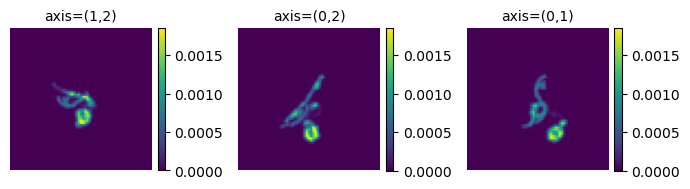

(65, 65, 65)
0.9999999403953552


In [3]:
plots.orthogonal_2D_projection_plot(f)

print(f.shape)
# print( np.sum(f) * dV )
print( np.sum(f) * ds**3 )

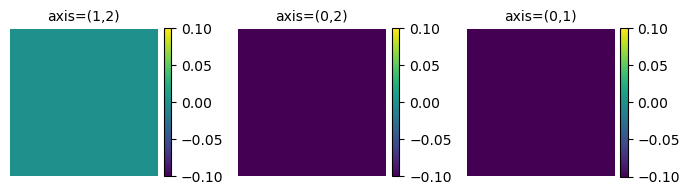

In [4]:
### EV: rotations without interpolation
# g = g[::-1, :, ::-1]  
# g = np.rot90(g)

plots.orthogonal_2D_projection_plot(f - g)

In [5]:
N = f.shape[0]
M = f.shape[0]   # grid size LxLxL
d = 3            # dimensons
max_l = M//2

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

In [6]:
importlib.reload(alignments)

c = alignments.align_l2(np.flip(f, axis=2), np.flip(g, axis=2), fle)

evaluate_t, step 1:  1.0503249168395996
step 2:  2.8722901344299316
correlation R=0:  6.177408876913211e-10
all correlation:  3.423169029546244e-11
everything else:  4.104741811752319


In [7]:
print(f.shape)

(65, 65, 65)


In [8]:
# plt.plot( c.flatten() )
# plt.plot(c[:, :, 0].flatten())

---

Approximation of inner product of $f$, $g$ :

$$ \langle f, g \rangle = \iiint f(x,y,z) g(x,y,z) dV $$ </br>

$$ \langle f, g \rangle \approx \sum_{i,j,k} f_{ijk} g_{ijk} \Delta V $$

---

In [9]:
print(" gt corr: ", np.sum(f * g) * dV)

# print("est corr: ", np.amax(c)*dV)
print("est corr: ", np.amax(c))

# print((np.sum(f * g) * dV / (np.amax(c))))

print("relative error: ",  np.abs(np.sum(f*g)*dV - np.amax(c)) /  np.sum(f*g)*dV )

# print("est corr: ", np.amax(c)*65**1.5*2*np.pi)
# print("est corr: ", np.amax(c)*128**3*dV)

 gt corr:  6.466815834500604e-10
est corr:  6.177408876913211e-10
relative error:  3.465252100102039e-11


In [10]:
### as distance
# np.linalg.norm(f - g)**2

(np.linalg.norm(f)**2 + np.linalg.norm(g)**2 - 2*np.sum(f * g))*dV

8.524528041324472e-17

In [11]:
print(" ||f||^2 :", np.linalg.norm(f)**2)
print(" ||g||^2 :", np.linalg.norm(g)**2)
print(" <f, g>  :", 2*np.sum(f * g))

 ||f||^2 : 2.323979759617464e-05
 ||g||^2 : 2.323979759617464e-05
 <f, g>  : 4.6479592128889635e-05


In [12]:
### this should be approximately zero ?

# dists = (np.linalg.norm(f)**2*dV + np.linalg.norm(g)**2*dV - 2*np.amax(c))/np.linalg.norm(f)**2

dists = (np.linalg.norm(f)**2 + np.linalg.norm(g)**2) * dV - 2*np.amax(c)


np.amin(dists)

5.788147676275897e-11

In [13]:
### I think this is the value we want to match from FRM

np.sum(f * g)*dV

6.466815834500604e-10

In [14]:
### if just comparing correlation, should look at the maximum

# # ignore this:
# np.amax( c) #* 4*np.pi    ### 4pi makes it approx equal for f = g ?

np.amax(c)

6.177408876913211e-10

In [15]:
np.linalg.norm(f)**2 * dV

6.466816260727006e-10

In [36]:
np.max(c) / (np.linalg.norm(f) * np.linalg.norm(g))

2.658116437973236e-05

---


<!-- $$ \iint_{\mathbb{R}^2} f( R_{\theta , \varphi}^\top} (x,y,z) )dxdydz $$ -->

$$ \iint_{\mathbb{R}^2} f( R^\top_{\theta , \varphi} (x,y,z)  )dxdy   $$

---

In [16]:
f_rt = transforms.Transform(f, d=3).radon_transform()[0]

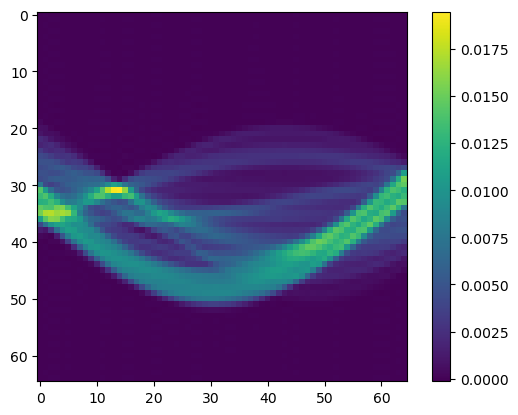

In [17]:
plt.imshow(f_rt[0])
plt.colorbar()
plt.show()

In [18]:
# np.sum(f_rt[0, :, 0]) * (((2 - 2/N)**2) / (N**2))**-1
# np.sum(f_rt[0, :, 0]) * ( N**2 / (2 - 2/N)**2 )

In [19]:
### EV: if I remove the normalization from the transforms.py script
###     then the projections match if I do np.sum(f) * dA / 4 [... but why divide by 4]
###     or equivalently if I multiply dV instead of dA ?

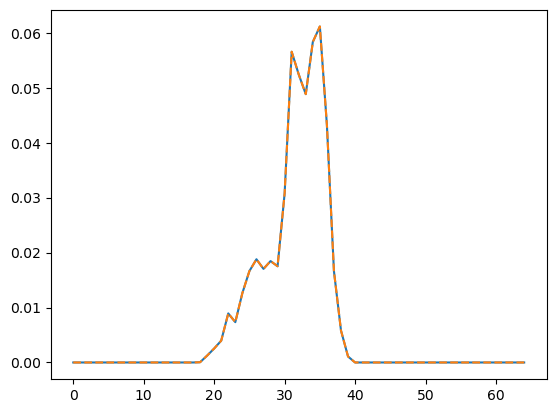

In [20]:
dA = ds**2
# dA = 1

plt.plot( f_rt[0, :, 0] * dA  )

plt.plot( np.sum(f, axis=(0,1)) * dA, '--' )

In [21]:
np.sum( np.sum(f, axis=(0,1)) * ds**2 ) * ds

0.9999999403953552

In [22]:
### EV: how do I make alignment_matrix_from_distances return the identity for max_L2 = R_0

# z = np.zeros((10,10,10))
# # z[0,0,0] = 1
# z[0,0,0] = 1
# q = alignments.alignment_matrix_from_distances(z)
# np.round(q, 3)
# A = np.arange(3*3).reshape(3,3)
# A
# np.round(q @ A, 3)